# Varianza fusionable y cancelación
Pregunta: ¿una traslación grande destruye la varianza computada? Se auditan algoritmos clásicos, sin novedad algorítmica. Hipótesis: el resumen desplazado conserva error absoluto <=1e-10 hasta offset1e12 para el fixture determinista. No se promete invariancia exacta en coma flotante.

In [1]:
import json,csv
from pathlib import Path
from IPython.display import display,Image
s=json.loads(Path('results/summary.json').read_text())
print(json.dumps(s,indent=2))

{
  "cases": 40,
  "max_error_representable": {
    "numpy_two_pass": 0.0,
    "ordinary_welford": 8.35407990962267e-06,
    "raw_moments": 1.25,
    "shifted_merge127": 2.220446049250313e-16,
    "shifted_stream": 1.1102230246251565e-15
  },
  "representation_loss": [
    {
      "n": 128,
      "offset": 1e+16,
      "method": "shifted_stream",
      "variance": 2.7499999999999996,
      "oracle": 2.75,
      "abs_error": 4.440892098500626e-16,
      "intended_error": 1.4999999999999996,
      "ns": 222606,
      "python_peak_bytes": 272
    },
    {
      "n": 4096,
      "offset": 1e+16,
      "method": "shifted_stream",
      "variance": 2.7500000000000053,
      "oracle": 2.75,
      "abs_error": 5.329070518200751e-15,
      "intended_error": 1.5000000000000053,
      "ns": 15700102,
      "python_peak_bytes": 336
    }
  ],
  "environment": {
    "python": "3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]",
    "platform": "Linux-6.18.55-x86_64-with-glibc2.39",
    "numpy":

## Métodos
M2 se actualiza con Welford sobre diferencias respecto al primer dato; Chan permite fusionar particiones. Decimal80 calcula el oráculo sobre los floats recibidos, no sobre números originales ya redondeados. ddof=0.

In [2]:
rows=list(csv.DictReader(Path('results/raw.csv').open()))
print([r for r in rows if r['n']=='4096' and r['offset']=='1000000000000.0'])

[{'n': '4096', 'offset': '1000000000000.0', 'method': 'raw_moments', 'variance': '0.0', 'oracle': '1.25', 'abs_error': '1.25', 'intended_error': '1.25', 'ns': '292131', 'python_peak_bytes': '440'}, {'n': '4096', 'offset': '1000000000000.0', 'method': 'numpy_two_pass', 'variance': '1.25', 'oracle': '1.25', 'abs_error': '0.0', 'intended_error': '0.0', 'ns': '191239', 'python_peak_bytes': '67088'}, {'n': '4096', 'offset': '1000000000000.0', 'method': 'ordinary_welford', 'variance': '1.2500011360025383', 'oracle': '1.25', 'abs_error': '1.1360025382600725e-06', 'intended_error': '1.1360025382600725e-06', 'ns': '1737064', 'python_peak_bytes': '144'}, {'n': '4096', 'offset': '1000000000000.0', 'method': 'shifted_stream', 'variance': '1.250000000000001', 'oracle': '1.25', 'abs_error': '1.1102230246251565e-15', 'intended_error': '1.1102230246251565e-15', 'ns': '9616333', 'python_peak_bytes': '336'}, {'n': '4096', 'offset': '1000000000000.0', 'method': 'shifted_merge127', 'variance': '1.24999999

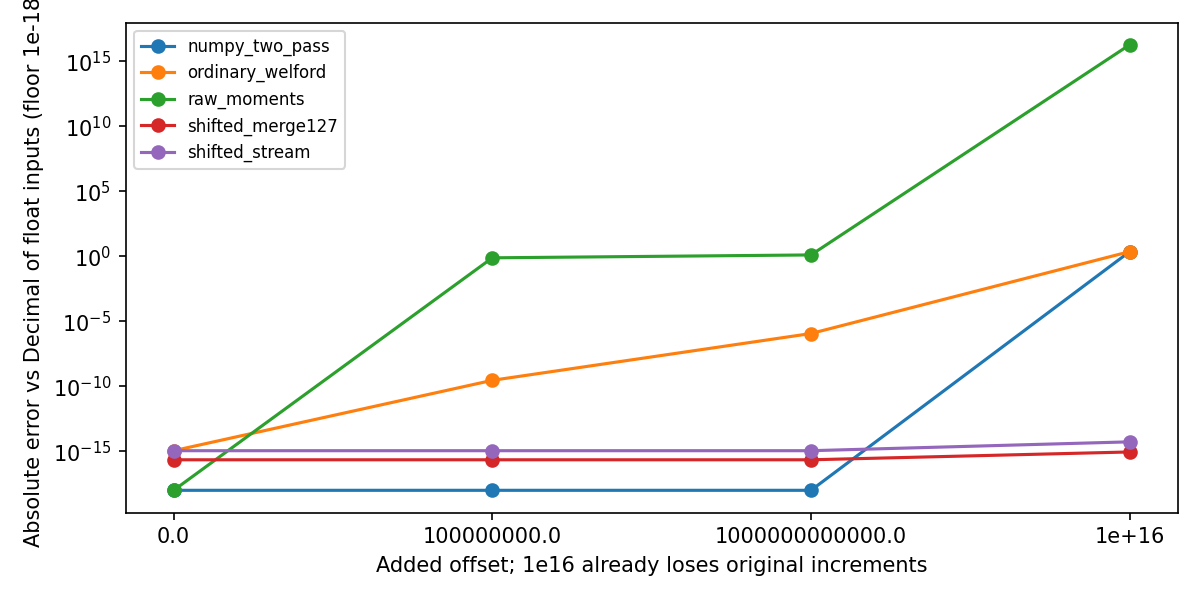

In [3]:
display(Image(filename='results/audit.png'))

## Resultado negativo y conclusión
A1e16 los incrementos originales 0,1,2,3 no son todos representables. Ningún algoritmo recupera datos perdidos. NumPy dos pasadas es un baseline fuerte; no se afirma superioridad general. Tiempos de una llamada con tracemalloc son diagnósticos, no ranking de velocidad. Prototipo reproducible, sin validación operacional.

In [4]:
assert s['max_error_representable']['shifted_stream']<=1e-10
assert s['max_error_representable']['shifted_merge127']<=1e-10
print('Hipótesis local verificada; error de representación:',s['representation_loss'])

Hipótesis local verificada; error de representación: [{'n': 128, 'offset': 1e+16, 'method': 'shifted_stream', 'variance': 2.7499999999999996, 'oracle': 2.75, 'abs_error': 4.440892098500626e-16, 'intended_error': 1.4999999999999996, 'ns': 222606, 'python_peak_bytes': 272}, {'n': 4096, 'offset': 1e+16, 'method': 'shifted_stream', 'variance': 2.7500000000000053, 'oracle': 2.75, 'abs_error': 5.329070518200751e-15, 'intended_error': 1.5000000000000053, 'ns': 15700102, 'python_peak_bytes': 336}]
